In [1]:

from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

project_dir = Path.cwd()
if not (project_dir / "data" / "power_plant.csv").exists():
    project_dir = project_dir.parent

df = pd.read_csv(project_dir / "data" / "power_plant.csv")

# Remove exact duplicates before splitting
df = df.drop_duplicates().reset_index(drop=True)

features = ["AT", "V", "AP", "RH"]
target = "PE"

X = df[features]
y = df[target]

# 60% train, 20% validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# Baseline model
model = LinearRegression()
model.fit(X_train, y_train)

val_predictions = model.predict(X_val)

mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
r2 = r2_score(y_val, val_predictions)

print("\nLinear Regression — Validation Results")
print(f"MAE:  {mae:.4f} MW")
print(f"RMSE: {rmse:.4f} MW")
print(f"R²:   {r2:.4f}")


Training samples: 5715
Validation samples: 1906
Test samples: 1906

Linear Regression — Validation Results
MAE:  3.5559 MW
RMSE: 4.5085 MW
R²:   0.9280


In [2]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))
rf_r2 = r2_score(y_val, rf_predictions)

print("Random Forest — Validation Results")
print(f"MAE:  {rf_mae:.4f} MW")
print(f"RMSE: {rf_rmse:.4f} MW")
print(f"R²:   {rf_r2:.4f}")


Random Forest — Validation Results
MAE:  2.5081 MW
RMSE: 3.5114 MW
R²:   0.9563


In [4]:

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))
xgb_r2 = r2_score(y_val, xgb_predictions)

print("XGBoost — Validation Results")
print(f"MAE:  {xgb_mae:.4f} MW")
print(f"RMSE: {xgb_rmse:.4f} MW")
print(f"R²:   {xgb_r2:.4f}")


XGBoost — Validation Results
MAE:  2.4787 MW
RMSE: 3.4050 MW
R²:   0.9589


In [5]:

results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2
    }
])

results = results.sort_values("RMSE").reset_index(drop=True)

display(results.round(4))

print("Best validation model:", results.iloc[0]["Model"])


,Model,MAE,RMSE,R2
0,XGBoost,2.4787,3.4050,0.9589
1,Random Forest,2.5081,3.5114,0.9563
2,Linear Regression,3.5559,4.5085,0.9280


Best validation model: XGBoost


In [6]:

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_lambda": [1, 5, 10]
}

search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ),
    param_distributions=param_distributions,
    n_iter=25,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print(f"Best CV RMSE: {-search.best_score_:.4f} MW")


Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best parameters:
{'subsample': 0.9, 'reg_lambda': 1, 'n_estimators': 700, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
Best CV RMSE: 3.3709 MW


In [7]:

best_xgb = search.best_estimator_

tuned_predictions = best_xgb.predict(X_val)

tuned_mae = mean_absolute_error(y_val, tuned_predictions)
tuned_rmse = np.sqrt(
    mean_squared_error(y_val, tuned_predictions)
)
tuned_r2 = r2_score(y_val, tuned_predictions)

print("Tuned XGBoost — Validation Results")
print(f"MAE:  {tuned_mae:.4f} MW")
print(f"RMSE: {tuned_rmse:.4f} MW")
print(f"R²:   {tuned_r2:.4f}")

print("\nOriginal XGBoost RMSE:", round(xgb_rmse, 4))
print("Tuned XGBoost RMSE:", round(tuned_rmse, 4))
print("RMSE improvement:", round(xgb_rmse - tuned_rmse, 4))


Tuned XGBoost — Validation Results
MAE:  2.2454 MW
RMSE: 3.1599 MW
R²:   0.9646

Original XGBoost RMSE: 3.405
Tuned XGBoost RMSE: 3.1599
RMSE improvement: 0.2451


In [8]:

all_results = pd.concat([
    results,
    pd.DataFrame([{
        "Model": "Tuned XGBoost",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2": tuned_r2
    }])
], ignore_index=True)

all_results = all_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(all_results.round(4))

print(
    "Best validation model:",
    all_results.iloc[0]["Model"]
)


,Model,MAE,RMSE,R2
0,Tuned XGBoost,2.2454,3.1599,0.9646
1,XGBoost,2.4787,3.4050,0.9589
2,Random Forest,2.5081,3.5114,0.9563
3,Linear Regression,3.5559,4.5085,0.9280


Best validation model: Tuned XGBoost


In [9]:

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Final model: train + validation data
final_model = XGBRegressor(
    **search.best_params_,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

final_model.fit(X_train_val, y_train_val)

# Test set is evaluated only after model selection
test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)
test_r2 = r2_score(y_test, test_predictions)

print("FINAL XGBOOST — TEST RESULTS")
print(f"MAE:  {test_mae:.4f} MW")
print(f"RMSE: {test_rmse:.4f} MW")
print(f"R²:   {test_r2:.4f}")


FINAL XGBOOST — TEST RESULTS
MAE:  2.2792 MW
RMSE: 3.2733 MW
R²:   0.9635


In [10]:

from pathlib import Path
import joblib

model_dir = project_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "poweryield_model.joblib"

joblib.dump(final_model, model_path)

print("Model saved to:", model_path)
print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")


Model saved to: c:\Users\Esila Nur Demirci\Documents\ML_Zoomcamp\Mid-Term-Project\PowerYield-ML\models\poweryield_model.joblib
Model size: 2432.18 KB


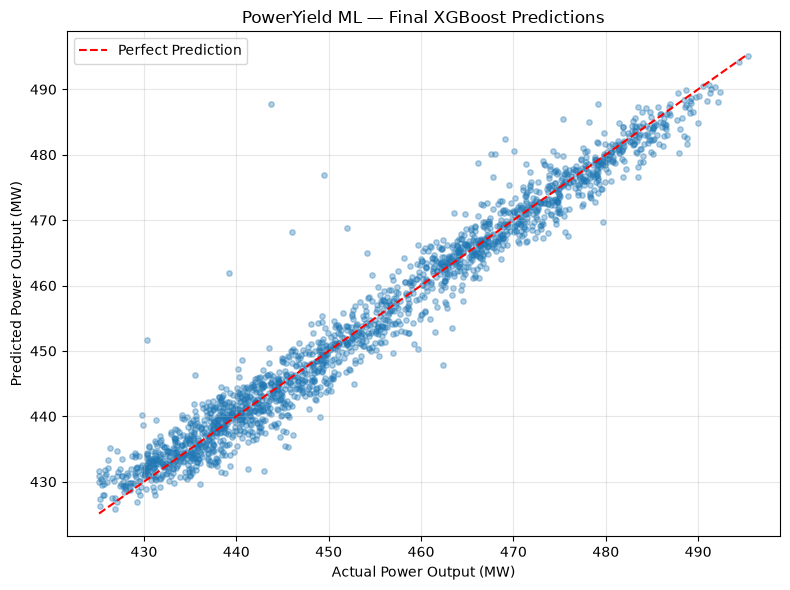

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.35,
    s=15
)

minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Predicted Power Output (MW)")
plt.title("PowerYield ML — Final XGBoost Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import sys
print(sys.executable)


c:\Users\Esila Nur Demirci\Downloads\.venv\Scripts\python.exe
